In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/drive/MyDrive/slr_project/src

In [2]:
%%writefile /content/drive/MyDrive/slr_project/src/features.py
"""Shared feature code for training (Colab) and the real-time/Streamlit app."""
import numpy as np
import pandas as pd

SEQ_LEN = 32
N_FEATURES = 258   # pose 33*4 + left hand 21*3 + right hand 21*3


# ---------- MediaPipe landmarker ----------
def make_landmarker(model_path):
    import mediapipe as mp
    options = mp.tasks.vision.HolisticLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=model_path),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        min_pose_detection_confidence=0.5,
        min_hand_landmarks_confidence=0.5)
    return mp.tasks.vision.HolisticLandmarker.create_from_options(options)


# ---------- keypoint extraction ----------
def lm_array(lms, n, with_vis):
    """Flatten a landmark list into a vector; zeros if not detected."""
    if lms and isinstance(lms[0], (list, tuple)):
        lms = lms[0]
    if not lms or len(lms) != n:
        return np.zeros(n * (4 if with_vis else 3))
    if with_vis:
        return np.array([[l.x, l.y, l.z, l.visibility or 0.0] for l in lms]).flatten()
    return np.array([[l.x, l.y, l.z] for l in lms]).flatten()


def extract_keypoints(result):
    """HolisticLandmarkerResult -> vector of 258 values."""
    pose = lm_array(result.pose_landmarks, 33, True)
    lh = lm_array(result.left_hand_landmarks, 21, False)
    rh = lm_array(result.right_hand_landmarks, 21, False)
    return np.concatenate([pose, lh, rh])


# ---------- frame selection ----------
def select_frames(frames, start, end, n=SEQ_LEN):
    """Trim to the sign (frame_start/frame_end) and sample n evenly spaced frames."""
    total = len(frames)
    s = int(start) - 1 if pd.notna(start) and start > 0 else 0    # frame_start is 1-indexed
    e = int(end) - 1 if pd.notna(end) and end > 0 else total - 1  # end <= 0 means "to the end"
    s = max(0, min(s, total - 1))
    e = max(s, min(e, total - 1))
    idx = np.linspace(s, e, n).astype(int)
    return [frames[i] for i in idx]


# ---------- normalization ----------
def normalize(feats):
    """feats: (T, 258). Center on the shoulder midpoint, scale by shoulder width."""
    f = feats.astype(np.float32).copy()
    pose = f[:, :132].reshape(-1, 33, 4).copy()
    ls, rs = pose[:, 11, :3], pose[:, 12, :3]               # left / right shoulder
    center = (ls + rs) / 2
    scale = np.linalg.norm(ls[:, :2] - rs[:, :2], axis=1)
    scale[scale < 1e-3] = 1.0                                # pose missing -> no scaling

    def adjust(block, n_points, n_vals):
        pts = block.reshape(-1, n_points, n_vals).copy()
        xyz = pts[:, :, :3]
        valid = (xyz != 0).any(axis=2, keepdims=True)         # keep missing points at zero
        pts[:, :, :3] = np.where(valid, (xyz - center[:, None, :]) / scale[:, None, None], 0)
        return pts.reshape(len(block), -1)

    return np.concatenate([adjust(f[:, :132], 33, 4),
                           adjust(f[:, 132:195], 21, 3),
                           adjust(f[:, 195:258], 21, 3)], axis=1)

Overwriting /content/drive/MyDrive/slr_project/src/features.py


In [3]:
%%writefile /content/drive/MyDrive/slr_project/src/model.py
"""LSTM/GRU model for WLASL100 sign recognition."""
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

from features import SEQ_LEN, N_FEATURES, normalize

# Final configuration chosen in Phase 3 (hands-only, normalized, 3-seed mean ~45% val top-1)
FINAL_MODEL_KW = dict(act='tanh', units=(128, 256, 128), dropout=0.5, dense=(128,))
FINAL_AUGMENT_COPIES = 8
HAND_SLICE = slice(132, 258)      # columns of the left + right hand inside the 258-vector


def build_model(n_classes, units=(64, 128, 64), act='relu', dropout=0.0, dense=(64, 32),
                bidirectional=False, rnn='lstm', lr=1e-3, label_smoothing=0.0,
                input_shape=(SEQ_LEN, N_FEATURES)):
    """Stacked recurrent classifier.

    Defaults reproduce the original baseline (LSTM 64-128-64, relu, Dense 64-32).
    The last recurrent layer returns one vector for the whole clip; the earlier
    ones return full sequences so the next layer can keep reading over time.
    """
    Rnn = layers.LSTM if rnn == 'lstm' else layers.GRU
    m = models.Sequential([layers.Input(shape=input_shape)])
    for i, u in enumerate(units):
        last = (i == len(units) - 1)
        layer = Rnn(u, return_sequences=not last, activation=act)
        m.add(layers.Bidirectional(layer) if bidirectional else layer)
        if dropout:
            m.add(layers.Dropout(dropout))
    for d in dense:
        m.add(layers.Dense(d, activation='relu'))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(n_classes, activation='softmax'))
    m.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
        metrics=['categorical_accuracy',
                 tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top5')])
    return m


def prepare_input(seq_258, feature_slice=HAND_SLICE):
    """Turn raw keypoints (32, 258) into model input.

    Order matters: normalize on all 258 values first (it needs the shoulders from
    the pose), THEN keep only the columns the model was trained on.
    Used by the evaluation notebook and by the real-time / Streamlit app.
    """
    x = normalize(np.asarray(seq_258, dtype=np.float32))
    return x[:, feature_slice]

Overwriting /content/drive/MyDrive/slr_project/src/model.py


In [5]:
%%writefile /content/drive/MyDrive/slr_project/src/augment.py
"""Keypoint-sequence augmentation (applied to NORMALIZED 258-value frames)."""
import numpy as np

N_POSE, N_HAND = 33, 21


def coord_indices():
    """Column indices of all x, y and z values in the 258-vector.

    Layout: pose 33x(x,y,z,visibility) = 132, then left hand 21x(x,y,z) = 63,
    then right hand 21x(x,y,z) = 63. Visibility columns are excluded.
    Each returned array has 75 entries (33 pose + 42 hand points).
    """
    pose = np.arange(N_POSE * 4).reshape(N_POSE, 4)
    hands = np.arange(N_POSE * 4, N_POSE * 4 + 2 * N_HAND * 3).reshape(2 * N_HAND, 3)
    xi = np.concatenate([pose[:, 0], hands[:, 0]])
    yi = np.concatenate([pose[:, 1], hands[:, 1]])
    zi = np.concatenate([pose[:, 2], hands[:, 2]])
    return xi, yi, zi


XI, YI, ZI = coord_indices()
ALL_COORDS = np.concatenate([XI, YI, ZI])


def augment(seq, rng):
    """Return one randomly modified copy of a (T, 258) sequence.

    Transforms: time warp (random crop + resample), scale, small rotation in the
    x-y plane, shift, and noise. Missing landmarks (zeros) stay zero.
    """
    T = len(seq)
    a, b = rng.integers(0, 4), T - 1 - rng.integers(0, 4)
    s = seq[np.linspace(a, b, T).astype(int)].copy()        # time warp
    present = (s != 0)                                       # remember which values are real

    s[:, ALL_COORDS] *= rng.uniform(0.9, 1.1)                # scale

    ang = np.deg2rad(rng.uniform(-10, 10))                   # rotation
    x, y = s[:, XI].copy(), s[:, YI].copy()
    s[:, XI] = x * np.cos(ang) - y * np.sin(ang)
    s[:, YI] = x * np.sin(ang) + y * np.cos(ang)

    s[:, XI] += rng.uniform(-0.1, 0.1)                       # shift
    s[:, YI] += rng.uniform(-0.1, 0.1)

    s[:, ALL_COORDS] += rng.normal(0, 0.005, size=(T, len(ALL_COORDS)))   # noise
    return (s * present).astype('float32')                   # missing points stay zero


def make_augmented(X, y, copies=4, seed=0):
    """Original data plus `copies` augmented versions of every sequence."""
    rng = np.random.default_rng(seed)
    Xs, ys = [X], [y]
    for _ in range(copies):
        Xs.append(np.stack([augment(x, rng) for x in X]))
        ys.append(y)
    return np.concatenate(Xs), np.concatenate(ys)

Writing /content/drive/MyDrive/slr_project/src/augment.py


In [4]:
import os, sys, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

BASE = '/content/drive/MyDrive/slr_project'
os.makedirs(f'{BASE}/eval', exist_ok=True)

sys.path.append(f'{BASE}/src')            # reads features.py and model.py from Drive
from features import normalize, SEQ_LEN
from model import prepare_input, HAND_SLICE

In [5]:
actions = np.load(f'{BASE}/actions.npy', allow_pickle=True)
cfg = json.load(open(f'{BASE}/models/model_config.json'))
model = tf.keras.models.load_model(f'{BASE}/models/best_model.keras')
print(cfg)

def load_split(split):
    d = np.load(f'{BASE}/processed_{split}.npz', allow_pickle=True)
    raw = d['X'].astype('float32')
    X = np.stack([prepare_input(x) for x in raw]).astype('float32')    # normalize, then keep the hand columns
    return dict(X=X, raw=raw, y=d['y'].astype(int), vids=d['video_ids'], signers=d['signer_ids'])

data = {s: load_split(s) for s in ['train', 'val', 'test']}
for s, d in data.items():
    print(s, d['X'].shape)           # (n, 32, 126)

{'seq_len': 32, 'n_features': 126, 'feature_slice': [132, 258], 'normalize': True, 'model': 'final_seed2', 'val_top1_mean': 0.4525, 'val_top1_std': 0.0252, 'val_top5_mean': 0.6909, 'val_top5_std': 0.0278}
train (748, 32, 126)
val (165, 32, 126)
test (100, 32, 126)


In [6]:
def predict(split):
    d = data[split]
    probs = model.predict(d['X'], verbose=0)
    d['probs'], d['pred'] = probs, probs.argmax(1)
    d['top5_hit'] = np.array([d['y'][i] in np.argsort(probs[i])[-5:] for i in range(len(d['y']))])

for s in ['val', 'test']:
    predict(s)

def wilson(k, n, z=1.96):
    """95% confidence interval for an accuracy of k correct out of n."""
    p = k / n
    c = (p + z*z/(2*n)) / (1 + z*z/n)
    h = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

rows = []
for s in ['val', 'test']:
    d = data[s]; y, pred = d['y'], d['pred']
    n, k = len(y), int((y == pred).sum())
    lo, hi = wilson(k, n)
    pm, rm, fm, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y, pred, average='weighted', zero_division=0)
    rows.append(dict(split=s, n_videos=n, top1=round(k/n, 3), ci95=f'{lo:.2f}-{hi:.2f}',
                     top5=round(d['top5_hit'].mean(), 3),
                     precision_macro=round(pm, 3), recall_macro=round(rm, 3), f1_macro=round(fm, 3),
                     precision_weighted=round(pw, 3), recall_weighted=round(rw, 3), f1_weighted=round(fw, 3)))
summary = pd.DataFrame(rows)
summary.to_csv(f'{BASE}/eval/metrics_summary.csv', index=False)
summary.T

,0,1
split,val,test
n_videos,165,100
top1,0.473,0.34
ci95,0.40-0.55,0.25-0.44
top5,0.715,0.68
precision_macro,0.403,0.283
recall_macro,0.422,0.319
f1_macro,0.385,0.284
precision_weighted,0.494,0.335
recall_weighted,0.473,0.34


In [7]:
def per_class(split):
    d = data[split]
    rep = classification_report(d['y'], d['pred'], labels=list(range(len(actions))),
                                target_names=list(actions), output_dict=True, zero_division=0)
    df = pd.DataFrame(rep).T.iloc[:len(actions)]
    return df[['precision', 'recall', 'f1-score', 'support']]

pc_val, pc_test = per_class('val'), per_class('test')
pc_val.to_csv(f'{BASE}/eval/per_class_val.csv'); pc_test.to_csv(f'{BASE}/eval/per_class_test.csv')
pc_val.sort_values('f1-score', ascending=False).head(10)

,precision,recall,f1-score,support
accident,1.000000,1.0,1.0,2.0
brown,1.000000,1.0,1.0,1.0
dark,1.000000,1.0,1.0,1.0
hot,1.000000,1.0,1.0,2.0
jacket,1.000000,1.0,1.0,2.0
many,1.000000,1.0,1.0,1.0
son,1.000000,1.0,1.0,2.0
thin,1.000000,1.0,1.0,3.0
give,1.000000,1.0,1.0,2.0
yes,0.666667,1.0,0.8,2.0


In [8]:
hp = f'{BASE}/eval/history_final.json'
if os.path.exists(hp):
    h = json.load(open(hp))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
    ax[1].plot(h['categorical_accuracy'], label='train'); ax[1].plot(h['val_categorical_accuracy'], label='val')
    ax[1].set_title('Accuracy'); ax[1].legend()
    plt.tight_layout(); plt.savefig(f'{BASE}/eval/training_curves.png', dpi=150); plt.show()
else:
    print('no saved history: re-run one seed and save it as shown above')

no saved history: re-run one seed and save it as shown above


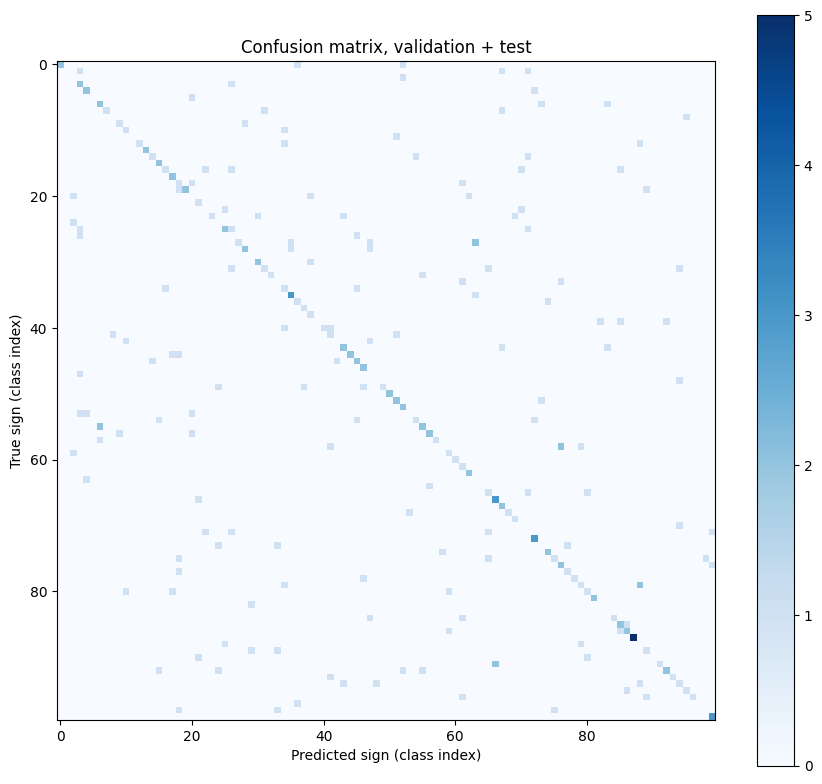

In [9]:
y_all = np.concatenate([data['val']['y'], data['test']['y']])
p_all = np.concatenate([data['val']['pred'], data['test']['pred']])
cm = confusion_matrix(y_all, p_all, labels=list(range(len(actions))))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap='Blues'); plt.colorbar(im)
ax.set_xlabel('Predicted sign (class index)'); ax.set_ylabel('True sign (class index)')
ax.set_title('Confusion matrix, validation + test')
plt.tight_layout(); plt.savefig(f'{BASE}/eval/confusion_matrix.png', dpi=150); plt.show()

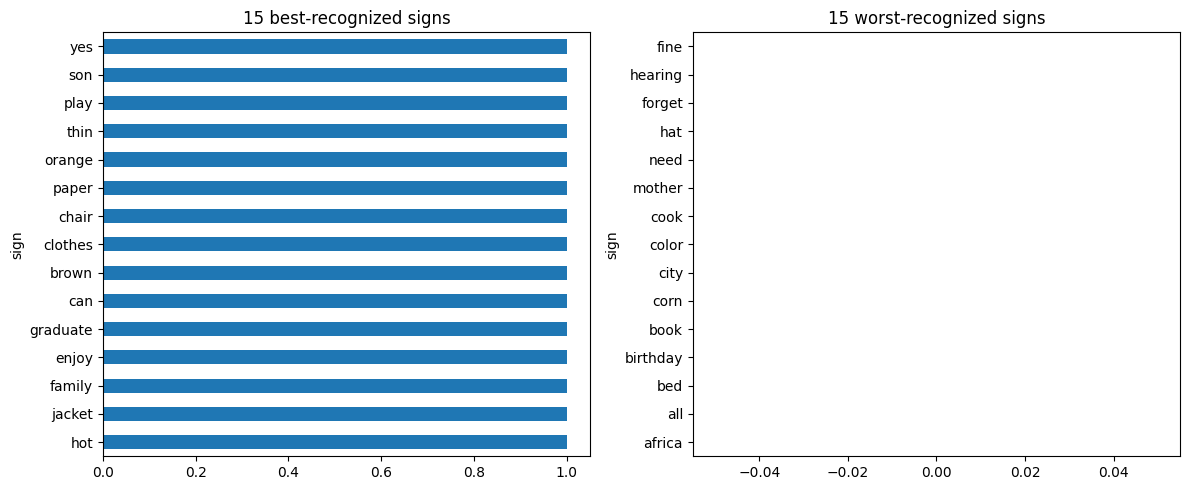

signs never recognized: 26 of 98


In [10]:
acc = pd.DataFrame({'sign': actions, 'n': cm.sum(1), 'correct': np.diag(cm)})
acc = acc[acc.n > 0].assign(acc=lambda d: d.correct / d.n).sort_values('acc')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
acc.tail(15).plot.barh(x='sign', y='acc', ax=ax[0], legend=False, title='15 best-recognized signs')
acc.head(15).plot.barh(x='sign', y='acc', ax=ax[1], legend=False, title='15 worst-recognized signs')
plt.tight_layout(); plt.savefig(f'{BASE}/eval/per_class_accuracy.png', dpi=150); plt.show()
acc.to_csv(f'{BASE}/eval/per_class_accuracy.csv', index=False)
print('signs never recognized:', (acc.correct == 0).sum(), 'of', len(acc))

In [11]:
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(actions[i], actions[j], off[i, j]) for i in range(len(actions)) for j in range(len(actions)) if off[i, j] > 0]
conf = pd.DataFrame(pairs, columns=['true_sign', 'predicted_as', 'count']).sort_values('count', ascending=False)
conf.head(15)

,true_sign,predicted_as,count
86,last,before,2
91,like,same,2
132,want,now,2
45,cousin,mother,2
116,shirt,thursday,2
4,africa,pizza,1
6,apple,corn,1
5,all,jacket,1
8,bed,city,1
9,before,pull,1


In [12]:
train_signers = set(data['train']['signers'])
sig = pd.DataFrame({
    'signer': np.concatenate([data['val']['signers'], data['test']['signers']]),
    'correct': (y_all == p_all)})
sig['seen_in_train'] = sig['signer'].isin(train_signers)

print(sig.groupby('seen_in_train')['correct'].agg(['mean', 'count']).round(3))

per_signer = sig.groupby('signer')['correct'].agg(['mean', 'count']).query('count >= 5').sort_values('mean')
print(per_signer.round(3))

                mean  count
seen_in_train              
False          0.333      6
True           0.425    259
         mean  count
signer              
115     0.167      6
41      0.167      6
116     0.200      5
12      0.217     23
59      0.364     11
0       0.400      5
56      0.400      5
2       0.429      7
31      0.444      9
13      0.455     11
11      0.457     35
10      0.474     19
36      0.500     10
4       0.529     17
21      0.600      5
118     0.650     20
32      0.667      6


In [13]:
d_v, d_t = data['val'], data['test']
meta = pd.DataFrame({
    'video_id': np.concatenate([d_v['vids'], d_t['vids']]),
    'split': ['val'] * len(d_v['y']) + ['test'] * len(d_t['y']),
    'signer': np.concatenate([d_v['signers'], d_t['signers']]),
    'true': actions[y_all], 'pred': actions[p_all],
    'confidence': np.concatenate([d_v['probs'].max(1), d_t['probs'].max(1)]).round(2),
    'true_in_top5': np.concatenate([d_v['top5_hit'], d_t['top5_hit']]),
    'hands_missing': np.concatenate([
        (d['raw'][:, :, 132:258] == 0).all(axis=2).mean(axis=1) for d in (d_v, d_t)]).round(2)})
meta['correct'] = meta.true == meta.pred
meta.to_csv(f'{BASE}/eval/predictions_val_test.csv', index=False)

print(meta.groupby('correct')[['confidence', 'hands_missing']].mean().round(2))
meta[~meta.correct].sort_values('confidence', ascending=False).head(15)

         confidence  hands_missing
correct                           
False          0.83           0.39
True           0.91           0.33


,video_id,split,signer,true,pred,confidence,true_in_top5,hands_missing,correct
2,51067,val,11,shirt,thursday,1.0,False,0.00,False
17,31751,val,31,kiss,basketball,1.0,False,0.34,False
9,15043,val,41,decide,last,1.0,False,0.44,False
25,45267,val,10,pull,doctor,1.0,True,0.28,False
20,69359,val,116,hat,apple,1.0,False,0.56,False
48,63669,val,13,woman,thanksgiving,1.0,True,0.56,False
28,40835,val,31,paint,kiss,1.0,True,0.25,False
226,21944,test,45,finish,dog,1.0,False,0.22,False
228,69431,test,117,pizza,color,1.0,False,0.50,False
122,01391,val,11,africa,orange,1.0,False,0.09,False


In [14]:
from IPython.display import Video, display

for _, r in meta[~meta.correct].sort_values('confidence', ascending=False).head(4).iterrows():
    print(f"true: {r.true} | predicted: {r.pred} | confidence {r.confidence} | signer {r.signer} | hands missing {r.hands_missing}")
    display(Video(f"{BASE}/videos100/{r.video_id}.mp4", embed=True, width=300))

true: shirt | predicted: thursday | confidence 1.0 | signer 11 | hands missing 0.0


true: kiss | predicted: basketball | confidence 1.0 | signer 31 | hands missing 0.34


true: decide | predicted: last | confidence 1.0 | signer 41 | hands missing 0.44


true: pull | predicted: doctor | confidence 1.0 | signer 10 | hands missing 0.28


In [16]:
rows = []
for s in [1, 2, 3]:
    m = tf.keras.models.load_model(f'{BASE}/content/ckpt_final_seed{s}.keras')
    for split in ['val', 'test']:
        p = m.predict(data[split]['X'], verbose=0); y = data[split]['y']
        rows.append(dict(seed=s, split=split, top1=round((p.argmax(1) == y).mean(), 3),
                         top5=round(np.mean([y[i] in np.argsort(p[i])[-5:] for i in range(len(y))]), 3)))
seed_df = pd.DataFrame(rows)
print(seed_df.pivot(index='seed', columns='split', values=['top1', 'top5']))
agg = seed_df.groupby('split')[['top1', 'top5']].agg(['mean', 'std']).round(3)
print(agg)
seed_df.to_csv(f'{BASE}/eval/seed_results.csv', index=False)

       top1         top5       
split  test    val  test    val
seed                           
1      0.41  0.424  0.68  0.661
2      0.34  0.473  0.68  0.715
3      0.46  0.461  0.70  0.697
        top1          top5       
        mean    std   mean    std
split                            
test   0.403  0.060  0.687  0.012
val    0.453  0.026  0.691  0.027


In [17]:
meta['conf_raw'] = np.concatenate([d_v['probs'].max(1), d_t['probs'].max(1)])
bins = pd.cut(meta['conf_raw'], [0, .5, .8, .95, .999, 1.0])
print(meta.groupby(bins, observed=True).agg(n=('correct', 'size'), accuracy=('correct', 'mean')).round(3))

                n  accuracy
conf_raw                   
(0.0, 0.5]     15     0.333
(0.5, 0.8]     63     0.222
(0.8, 0.95]    35     0.371
(0.95, 0.999]  96     0.406
(0.999, 1.0]   56     0.732


In [18]:
print(meta.groupby('correct')[['hands_missing', 'conf_raw']].mean().round(2))

print(meta.groupby('signer')
          .agg(n=('correct', 'size'), acc=('correct', 'mean'), hands_missing=('hands_missing', 'mean'))
          .query('n >= 10').round(2).sort_values('acc'))

         hands_missing  conf_raw
correct                         
False             0.39      0.83
True              0.33      0.91
         n   acc  hands_missing
signer                         
12      23  0.22           0.61
59      11  0.36           0.46
13      11  0.45           0.37
11      35  0.46           0.02
10      19  0.47           0.02
36      10  0.50           0.50
4       17  0.53           0.34
118     20  0.65           0.41


In [19]:
acc[acc.correct == 0].sort_values('n', ascending=False)[['sign', 'n']].head(30)

,sign,n
71,pizza,4
58,like,4
39,fine,3
53,kiss,3
98,year,3
73,pull,3
1,africa,3
20,city,3
22,color,2
26,corn,2


In [20]:
import json, tensorflow as tf
cfg_path = f'{BASE}/models/model_config.json'
cfg = json.load(open(cfg_path))
cfg.update(model_version='v1', seq_len=32, n_features=126, feature_slice=[132, 258], normalize=True,
           n_classes=int(len(actions)), tensorflow=tf.__version__,
           mediapipe='PASTE the version printed in your extraction notebook (print(mp.__version__))',
           trained_on='WLASL100 official train split, Kaggle copy (748 videos)')
json.dump(cfg, open(cfg_path, 'w'), indent=2)
print(cfg)

{'seq_len': 32, 'n_features': 126, 'feature_slice': [132, 258], 'normalize': True, 'model': 'final_seed2', 'val_top1_mean': 0.4525, 'val_top1_std': 0.0252, 'val_top5_mean': 0.6909, 'val_top5_std': 0.0278, 'model_version': 'v1', 'n_classes': 100, 'tensorflow': '2.21.0', 'mediapipe': 'PASTE the version printed in your extraction notebook (print(mp.__version__))', 'trained_on': 'WLASL100 official train split, Kaggle copy (748 videos)'}


In [21]:
import shutil
V1 = f'{BASE}/app_models/v1'
os.makedirs(V1, exist_ok=True)
for f in ['models/best_model.keras', 'models/model_config.json', 'models/label_map.json',
          'actions.npy', 'holistic_landmarker.task']:
    shutil.copy(f'{BASE}/{f}', V1)
print(os.listdir(V1))

from google.colab import files
for name, folder in [('model_v1', V1), ('src', f'{BASE}/src'), ('eval', f'{BASE}/eval')]:
    shutil.make_archive(f'/content/{name}', 'zip', folder)
    files.download(f'/content/{name}.zip')

['best_model.keras', 'model_config.json', 'label_map.json', 'actions.npy', 'holistic_landmarker.task']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>